LOOCV 1/22
LOOCV 2/22
LOOCV 3/22
LOOCV 4/22
LOOCV 5/22
LOOCV 6/22
LOOCV 7/22
LOOCV 8/22
LOOCV 9/22
LOOCV 10/22
LOOCV 11/22
LOOCV 12/22
LOOCV 13/22
LOOCV 14/22
LOOCV 15/22
LOOCV 16/22
LOOCV 17/22
LOOCV 18/22
LOOCV 19/22
LOOCV 20/22
LOOCV 21/22
LOOCV 22/22

PHYSICS-GUIDED MBVD RESULTS
Mean Curve MSE: 0.01659113367508049
Mean Resonance Error (MHz): 2.417717785598495
Mean Anti-Resonance Error (MHz): 1.4569510426680934


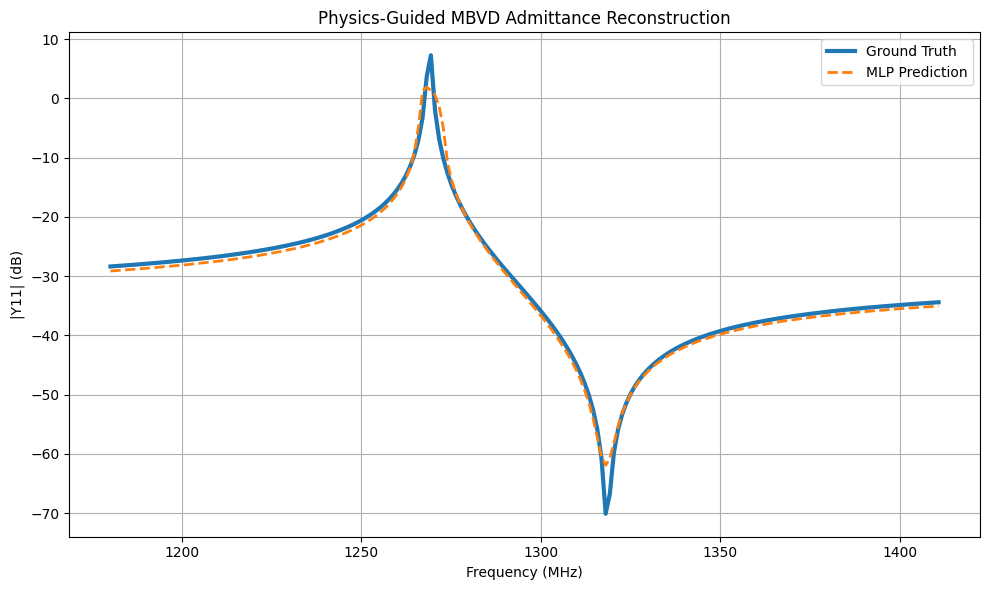

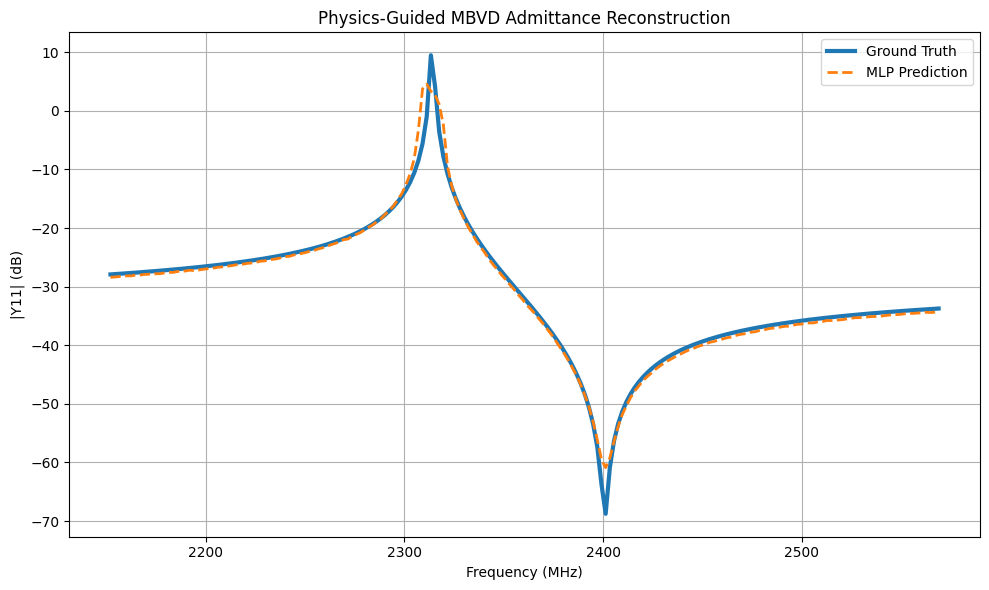

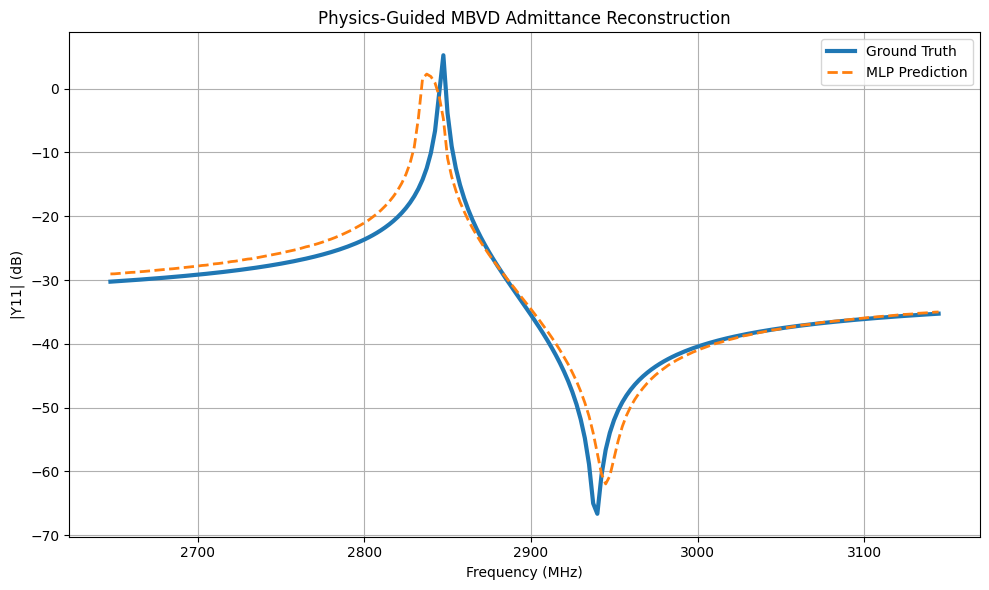

In [ ]:
#baseline
# =========================================================
# PHYSICS-GUIDED MBVD SURROGATE MODEL
# USING:
# (Cs, fr, Qs, Qp, R0, k2)
#
# ANALYTICAL RECONSTRUCTION:
# fa -> Cm -> Lm -> Rm -> Rs
#
# ANN INPUT:
# (Rm, Lm, Cm, Cs, R0, Rs)
#
# ANN OUTPUT:
# Y11(f)
# =========================================================

import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# =========================================================
# FULL REPRODUCIBILITY
# =========================================================
SEED = 0

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)

np.random.seed(SEED)

tf.keras.utils.set_random_seed(SEED)

tf.config.experimental.enable_op_determinism()

tf.get_logger().setLevel("ERROR")

# =========================================================
# CONSTANTS
# =========================================================
PI = np.pi

N_FREQ = 200

N_SYNTH = 120

# =========================================================
# REAL RESONATORS
# =========================================================
# Inputs:
# Cs, fr, Qs, Qp, R0, k2
# =========================================================
real_resonators = [

{"Cs":7.95e-13,"fr":2468e6,"Qs":887,"Qp":3770,"R0":0.257,"k2":0.080},
{"Cs":5.989e-13,"fr":2466e6,"Qs":1034,"Qp":1379,"R0":0.257,"k2":0.080},
{"Cs":3.981e-13,"fr":2468e6,"Qs":1994,"Qp":1052,"R0":0.257,"k2":0.085},
{"Cs":1.857e-12,"fr":2461e6,"Qs":935,"Qp":2513,"R0":0.257,"k2":0.081},
{"Cs":1.39e-12,"fr":2488e6,"Qs":804,"Qp":1732,"R0":0.257,"k2":0.084},
{"Cs":1.65e-12,"fr":2324e6,"Qs":1038,"Qp":1112,"R0":0.257,"k2":0.091},
{"Cs":1.70e-12,"fr":2324e6,"Qs":911,"Qp":1683,"R0":0.257,"k2":0.0855},
{"Cs":2.60e-12,"fr":1298e6,"Qs":1470,"Qp":2580,"R0":0.257,"k2":0.093},
{"Cs":2.03e-12,"fr":1487e6,"Qs":1249,"Qp":1966,"R0":0.257,"k2":0.097},
{"Cs":2.36e-12,"fr":1477e6,"Qs":904,"Qp":1153,"R0":0.257,"k2":0.096},
{"Cs":1.096e-12,"fr":1722e6,"Qs":2688,"Qp":3530,"R0":0.257,"k2":0.092},
{"Cs":3.01e-12,"fr":1443e6,"Qs":1353,"Qp":1585,"R0":0.257,"k2":0.091},
{"Cs":3.244e-12,"fr":1269e6,"Qs":1643,"Qp":1645,"R0":0.257,"k2":0.0891},
{"Cs":1.242e-12,"fr":2847e6,"Qs":906,"Qp":2170,"R0":0.257,"k2":0.0747},
{"Cs":1.592e-12,"fr":2467e6,"Qs":832,"Qp":2911,"R0":0.257,"k2":0.0846},
{"Cs":1.90e-12,"fr":2314e6,"Qs":1181,"Qp":2603,"R0":0.257,"k2":0.086},
{"Cs":2.132e-12,"fr":2074e6,"Qs":892,"Qp":3792,"R0":0.257,"k2":0.089},
{"Cs":2.47e-12,"fr":1719e6,"Qs":974,"Qp":4742,"R0":0.257,"k2":0.090},
{"Cs":1.07e-12,"fr":1723e6,"Qs":2291,"Qp":1939,"R0":0.257,"k2":0.093},
{"Cs":2.02e-12,"fr":1485e6,"Qs":1089,"Qp":6853,"R0":0.257,"k2":0.094},
{"Cs":1.57e-12,"fr":2467e6,"Qs":1095,"Qp":1312,"R0":0.257,"k2":0.0868},
{"Cs":1.58e-12,"fr":2092e6,"Qs":857,"Qp":1712,"R0":0.257,"k2":0.092}

]

# =========================================================
# SYNTHETIC RESONATOR GENERATION
# =========================================================
def generate_synthetic_resonators(n):

    resonators = []

    while len(resonators) < n:

        resonators.append({

            "Cs": np.random.uniform(0.5e-12,3.5e-12),

            "fr": np.random.uniform(1.2e9,2.9e9),

            "Qs": np.random.uniform(700,3000),

            "Qp": np.random.uniform(1000,7000),

            "R0": 0.257,

            "k2": np.random.uniform(0.074,0.10)

        })

    return resonators

# =========================================================
# PHYSICS-GUIDED MBVD RECONSTRUCTION
# =========================================================
def compute_mbvd_parameters(r):

    Cs = r["Cs"]

    fr = r["fr"]

    Qs = r["Qs"]

    Qp = r["Qp"]

    R0 = r["R0"]

    k2 = r["k2"]

    # =====================================================
    # ANTI-RESONANCE FREQUENCY
    # =====================================================
    fa = (

        2*fr

        /

        (

            1 +

            np.sqrt(

                1 - (16*k2)/(PI**2)

            )

        )

    )

    # =====================================================
    # ANGULAR FREQUENCIES
    # =====================================================
    wr = 2*PI*fr

    wa = 2*PI*fa

    # =====================================================
    # MOTIONAL CAPACITANCE
    # =====================================================
    Cm = Cs * ((fa/fr)**2 - 1)

    # =====================================================
    # MOTIONAL INDUCTANCE
    # =====================================================
    Lm = 1 / ((wr**2) * Cm)

    # =====================================================
    # MOTIONAL RESISTANCE
    # =====================================================
    Rm = wr * (Lm/Qs) - R0

    # =====================================================
    # STATIC BRANCH LOSS
    # =====================================================
    Rs = wa * (Lm/Qp) - Rm

    # =====================================================
    # SAFETY
    # =====================================================
    Rm = np.maximum(Rm,1e-6)

    Rs = np.maximum(Rs,1e-6)

    Cm = np.maximum(Cm,1e-18)

    Lm = np.maximum(Lm,1e-18)

    return Rm,Lm,Cm,Cs,R0,Rs,fa

# =========================================================
# MBVD ADMITTANCE RESPONSE
# =========================================================
def compute_Y11(r):

    Rm,Lm,Cm,Cs,R0,Rs,fa = compute_mbvd_parameters(r)

    fr = r["fr"]

    # =====================================================
    # FREQUENCY SWEEP
    # =====================================================
    f = np.linspace(

        fr*0.93,

        fa*1.07,

        N_FREQ

    )

    w = 2*PI*f

    # =====================================================
    # STATIC BRANCH
    # =====================================================
    Zs = R0 + 1/(1j*w*Cs)

    # =====================================================
    # MOTIONAL BRANCH
    # =====================================================
    Zm = (

        Rm +

        1/(1j*w*Cm) +

        1j*w*Lm

    )

    # =====================================================
    # PARALLEL COMBINATION
    # =====================================================
    Zp = 1/(1/Zs + 1/Zm)

    # =====================================================
    # TOTAL IMPEDANCE
    # =====================================================
    Ztotal = Rs + Zp

    # =====================================================
    # ADMITTANCE
    # =====================================================
    Y11 = np.abs(1/Ztotal)

    return Y11,f

# =========================================================
# EXTRACT RESONANCE / ANTI-RESONANCE
# =========================================================
def extract_frequencies(Y,f):

    fr = f[np.argmax(Y)]

    fa = f[np.argmin(Y)]

    return fr,fa

# =========================================================
# SURROGATE MODEL
# =========================================================
def build_model():

    tf.keras.backend.clear_session()

    model = tf.keras.Sequential([

        tf.keras.layers.Input((6,)),

        tf.keras.layers.Dense(
            96,
            activation="swish"
        ),

        tf.keras.layers.Dense(
            96,
            activation="swish"
        ),

        tf.keras.layers.Dense(
            128,
            activation="swish"
        ),

        tf.keras.layers.Dense(
            N_FREQ,
            activation="softplus"
        )

    ])

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),

        loss="mse"

    )

    return model

# =========================================================
# SYNTHETIC DATASET
# =========================================================
synthetic_resonators = generate_synthetic_resonators(N_SYNTH)

# =========================================================
# RESULTS STORAGE
# =========================================================
curve_mse = []

res_errors = []

anti_errors = []

example_results = []

# =========================================================
# LOOCV
# =========================================================
for i in range(len(real_resonators)):

    print(f"LOOCV {i+1}/{len(real_resonators)}")

    # =====================================================
    # TEST SAMPLE
    # =====================================================
    test_res = real_resonators[i]

    # =====================================================
    # TRAINING SET
    # =====================================================
    train_real = (

        real_resonators[:i] +

        real_resonators[i+1:]

    )

    train_res = train_real + synthetic_resonators

    X_train = []

    Y_train = []

    # =====================================================
    # BUILD TRAINING DATA
    # =====================================================
    for r in train_res:

        Rm,Lm,Cm,Cs,R0,Rs,fa = compute_mbvd_parameters(r)

        # =================================================
        # ANN INPUT
        # =================================================
        X_train.append([

            Rm,
            Lm,
            Cm,
            Cs,
            R0,
            Rs

        ])

        # =================================================
        # TARGET
        # =================================================
        Y_train.append(
            compute_Y11(r)[0]
        )

    X_train = np.array(X_train,np.float32)

    Y_train = np.array(Y_train,np.float32)

    # =====================================================
    # NORMALIZATION
    # =====================================================
    Xm = X_train.mean(axis=0)

    Xs = X_train.std(axis=0)

    Ym = Y_train.mean(axis=0)

    Ys = Y_train.std(axis=0)

    Xs = np.where(Xs < 1e-12,1.0,Xs)

    Ys = np.where(Ys < 1e-12,1.0,Ys)

    Xn = (X_train - Xm)/Xs

    Yn = (Y_train - Ym)/Ys

    # =====================================================
    # TEST SAMPLE
    # =====================================================
    Rm,Lm,Cm,Cs,R0,Rs,fa = compute_mbvd_parameters(test_res)

    Xt = np.array([[

        Rm,
        Lm,
        Cm,
        Cs,
        R0,
        Rs

    ]],dtype=np.float32)

    Xt = (Xt - Xm)/Xs

    # =====================================================
    # GROUND TRUTH
    # =====================================================
    Y_true,f = compute_Y11(test_res)

    # =====================================================
    # MODEL
    # =====================================================
    model = build_model()

    earlystop = tf.keras.callbacks.EarlyStopping(

        monitor="loss",

        patience=15,

        restore_best_weights=True

    )

    # =====================================================
    # TRAINING
    # =====================================================
    model.fit(

        Xn,
        Yn,

        epochs=120,

        batch_size=16,

        shuffle=True,

        verbose=0,

        callbacks=[earlystop]

    )

    # =====================================================
    # PREDICTION
    # =====================================================
    Y_pred = model.predict(

        Xt,
        verbose=0

    )[0]

    Y_pred = Y_pred*Ys + Ym

    # =====================================================
    # METRICS
    # =====================================================
    mse = np.mean((Y_true - Y_pred)**2)

    fr_true,fa_true = extract_frequencies(Y_true,f)

    fr_pred,fa_pred = extract_frequencies(Y_pred,f)

    curve_mse.append(mse)

    res_errors.append(

        abs(fr_true-fr_pred)/1e6

    )

    anti_errors.append(

        abs(fa_true-fa_pred)/1e6

    )

    # =====================================================
    # STORE RESULTS
    # =====================================================
    example_results.append({

        "f":f,

        "Y_true":Y_true,

        "Y_pred":Y_pred,

        "fr":test_res["fr"]

    })

# =========================================================
# FINAL RESULTS
# =========================================================
print("\n==============================")

print("PHYSICS-GUIDED MBVD RESULTS")

print("==============================")

print("Mean Curve MSE:",
      np.mean(curve_mse))

print("Mean Resonance Error (MHz):",
      np.mean(res_errors))

print("Mean Anti-Resonance Error (MHz):",
      np.mean(anti_errors))

# =========================================================
# SORT EXAMPLES
# =========================================================
example_results.sort(
    key=lambda x: x["fr"]
)

# =========================================================
# REPRESENTATIVE EXAMPLES
# =========================================================
indices = [

    0,

    len(example_results)//2,

    -1

]

# =========================================================
# PLOTS
# =========================================================
for idx in indices:

    ex = example_results[idx]

    plt.figure(figsize=(10,6))

    plt.plot(

        ex["f"]/1e6,

        20*np.log10(ex["Y_true"] + 1e-15),

        linewidth=3,

        label="Ground Truth"

    )

    plt.plot(

        ex["f"]/1e6,

        20*np.log10(ex["Y_pred"] + 1e-15),

        "--",

        linewidth=2,

        label="MLP Prediction"

    )

    plt.xlabel("Frequency (MHz)")

    plt.ylabel("|Y11| (dB)")

    plt.title(

        "Physics-Guided MBVD Admittance Reconstruction"

    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.show()

LOOCV 1/22
LOOCV 2/22
LOOCV 3/22
LOOCV 4/22
LOOCV 5/22
LOOCV 6/22
LOOCV 7/22
LOOCV 8/22
LOOCV 9/22
LOOCV 10/22
LOOCV 11/22
LOOCV 12/22
LOOCV 13/22
LOOCV 14/22
LOOCV 15/22
LOOCV 16/22
LOOCV 17/22
LOOCV 18/22
LOOCV 19/22
LOOCV 20/22
LOOCV 21/22
LOOCV 22/22

PHYSICS-GUIDED CNN RESULTS
Mean Curve MSE: 0.016611150259974703
Mean Resonance Error (MHz): 2.51468717769677
Mean Anti-Resonance Error (MHz): 1.4569510426680934


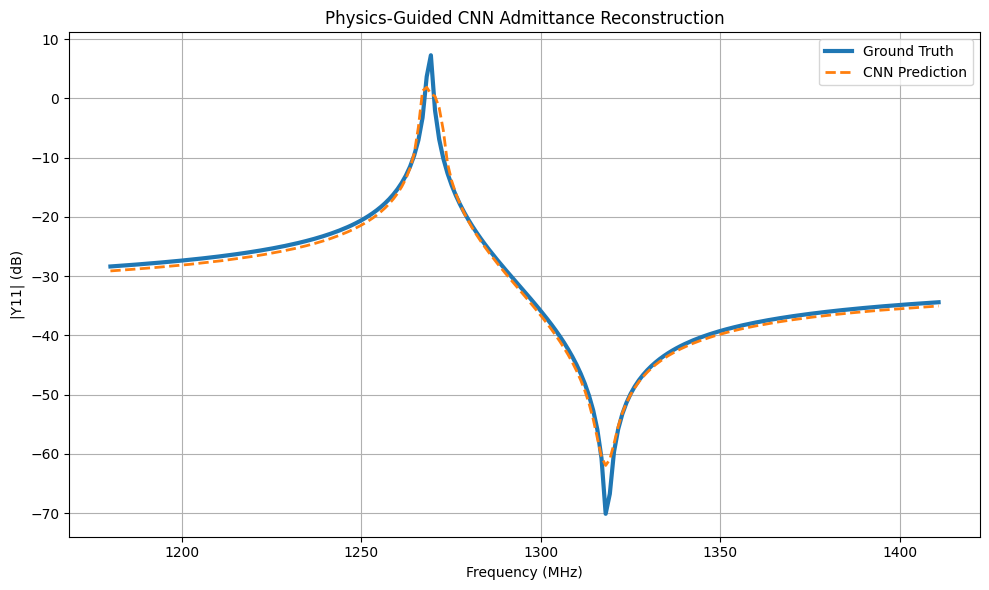

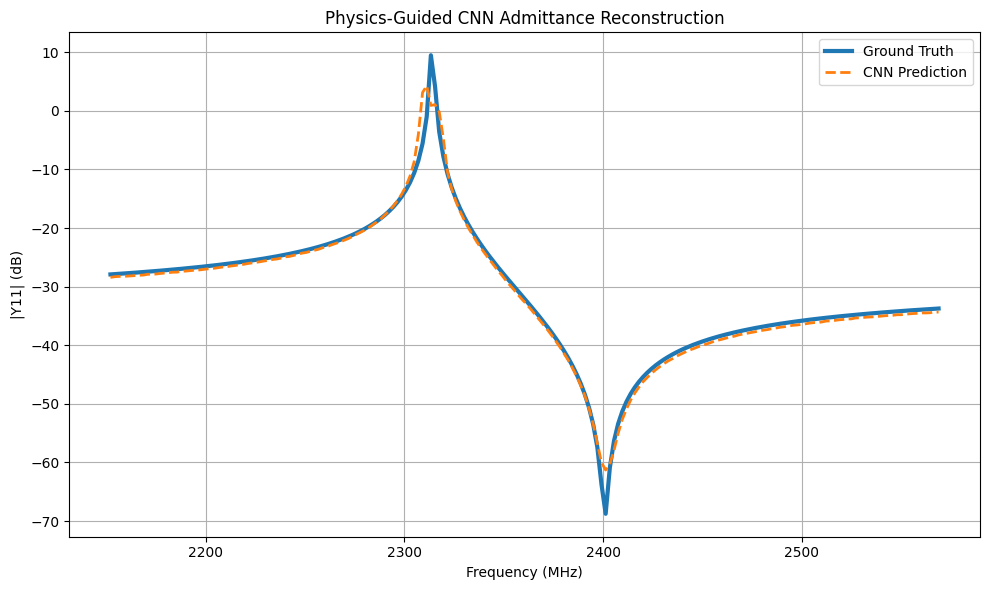

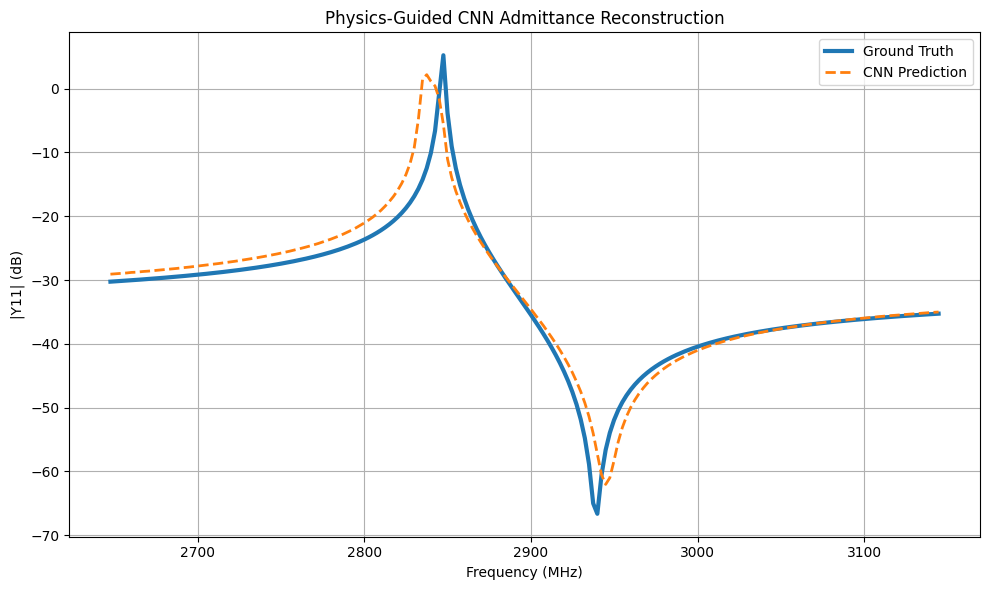

In [ ]:
#cnn
# =========================================================
# REPRODUCIBLE PHYSICS-GUIDED CNN
# WITH REPRESENTATIVE PLOTS
# =========================================================

import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# =========================================================
# FULL REPRODUCIBILITY
# =========================================================
SEED = 0

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)

np.random.seed(SEED)

tf.keras.utils.set_random_seed(SEED)

tf.config.experimental.enable_op_determinism()

tf.get_logger().setLevel("ERROR")

# =========================================================
# CONSTANTS
# =========================================================
PI = np.pi

N_FREQ = 200

N_SYNTH = 120

# =========================================================
# REAL RESONATORS
# =========================================================
real_resonators = [

{"Cs":7.95e-13,"fr":2468e6,"Qs":887,"Qp":3770,"R0":0.257,"k2":0.080},
{"Cs":5.989e-13,"fr":2466e6,"Qs":1034,"Qp":1379,"R0":0.257,"k2":0.080},
{"Cs":3.981e-13,"fr":2468e6,"Qs":1994,"Qp":1052,"R0":0.257,"k2":0.085},
{"Cs":1.857e-12,"fr":2461e6,"Qs":935,"Qp":2513,"R0":0.257,"k2":0.081},
{"Cs":1.39e-12,"fr":2488e6,"Qs":804,"Qp":1732,"R0":0.257,"k2":0.084},
{"Cs":1.65e-12,"fr":2324e6,"Qs":1038,"Qp":1112,"R0":0.257,"k2":0.091},
{"Cs":1.70e-12,"fr":2324e6,"Qs":911,"Qp":1683,"R0":0.257,"k2":0.0855},
{"Cs":2.60e-12,"fr":1298e6,"Qs":1470,"Qp":2580,"R0":0.257,"k2":0.093},
{"Cs":2.03e-12,"fr":1487e6,"Qs":1249,"Qp":1966,"R0":0.257,"k2":0.097},
{"Cs":2.36e-12,"fr":1477e6,"Qs":904,"Qp":1153,"R0":0.257,"k2":0.096},
{"Cs":1.096e-12,"fr":1722e6,"Qs":2688,"Qp":3530,"R0":0.257,"k2":0.092},
{"Cs":3.01e-12,"fr":1443e6,"Qs":1353,"Qp":1585,"R0":0.257,"k2":0.091},
{"Cs":3.244e-12,"fr":1269e6,"Qs":1643,"Qp":1645,"R0":0.257,"k2":0.0891},
{"Cs":1.242e-12,"fr":2847e6,"Qs":906,"Qp":2170,"R0":0.257,"k2":0.0747},
{"Cs":1.592e-12,"fr":2467e6,"Qs":832,"Qp":2911,"R0":0.257,"k2":0.0846},
{"Cs":1.90e-12,"fr":2314e6,"Qs":1181,"Qp":2603,"R0":0.257,"k2":0.086},
{"Cs":2.132e-12,"fr":2074e6,"Qs":892,"Qp":3792,"R0":0.257,"k2":0.089},
{"Cs":2.47e-12,"fr":1719e6,"Qs":974,"Qp":4742,"R0":0.257,"k2":0.090},
{"Cs":1.07e-12,"fr":1723e6,"Qs":2291,"Qp":1939,"R0":0.257,"k2":0.093},
{"Cs":2.02e-12,"fr":1485e6,"Qs":1089,"Qp":6853,"R0":0.257,"k2":0.094},
{"Cs":1.57e-12,"fr":2467e6,"Qs":1095,"Qp":1312,"R0":0.257,"k2":0.0868},
{"Cs":1.58e-12,"fr":2092e6,"Qs":857,"Qp":1712,"R0":0.257,"k2":0.092}

]

# =========================================================
# SYNTHETIC RESONATOR GENERATION
# =========================================================
def generate_synthetic_resonators(n):

    resonators = []

    while len(resonators) < n:

        resonators.append({

            "Cs": np.random.uniform(0.5e-12,3.5e-12),

            "fr": np.random.uniform(1.2e9,2.9e9),

            "Qs": np.random.uniform(700,3000),

            "Qp": np.random.uniform(1000,7000),

            "R0": 0.257,

            "k2": np.random.uniform(0.074,0.10)

        })

    return resonators

# =========================================================
# PHYSICS-GUIDED MBVD RECONSTRUCTION
# =========================================================
def compute_mbvd_parameters(r):

    Cs = r["Cs"]

    fr = r["fr"]

    Qs = r["Qs"]

    Qp = r["Qp"]

    R0 = r["R0"]

    k2 = r["k2"]

    # =====================================================
    # ANTI-RESONANCE FREQUENCY
    # =====================================================
    fa = (

        2*fr

        /

        (

            1 +

            np.sqrt(

                1 - (16*k2)/(PI**2)

            )

        )

    )

    wr = 2*PI*fr

    wa = 2*PI*fa

    # =====================================================
    # MOTIONAL CAPACITANCE
    # =====================================================
    Cm = Cs*((fa/fr)**2 -1)

    # =====================================================
    # MOTIONAL INDUCTANCE
    # =====================================================
    Lm = 1/((wr**2)*Cm)

    # =====================================================
    # MOTIONAL RESISTANCE
    # =====================================================
    Rm = wr*(Lm/Qs) - R0

    # =====================================================
    # STATIC BRANCH LOSS
    # =====================================================
    Rs = wa*(Lm/Qp) - Rm

    # =====================================================
    # SAFETY
    # =====================================================
    Rm = np.maximum(Rm,1e-6)

    Rs = np.maximum(Rs,1e-6)

    Cm = np.maximum(Cm,1e-18)

    Lm = np.maximum(Lm,1e-18)

    return Rm,Lm,Cm,Cs,R0,Rs,fa

# =========================================================
# MBVD RESPONSE
# =========================================================
def compute_Y11(r):

    fr = r["fr"]

    Rm,Lm,Cm,Cs,R0,Rs,fa = compute_mbvd_parameters(r)

    # =====================================================
    # FREQUENCY SWEEP
    # =====================================================
    f = np.linspace(

        fr*0.93,

        fa*1.07,

        N_FREQ

    )

    w = 2*PI*f

    # =====================================================
    # STATIC BRANCH
    # =====================================================
    Zs = R0 + 1/(1j*w*Cs)

    # =====================================================
    # MOTIONAL BRANCH
    # =====================================================
    Zm = Rm + 1/(1j*w*Cm) + 1j*w*Lm

    # =====================================================
    # PARALLEL COMBINATION
    # =====================================================
    Zp = 1/(1/Zs + 1/Zm)

    # =====================================================
    # TOTAL IMPEDANCE
    # =====================================================
    Ztotal = Rs + Zp

    # =====================================================
    # ADMITTANCE
    # =====================================================
    Y11 = np.abs(1/Ztotal)

    return Y11,f

# =========================================================
# EXTRACT RESONANCE / ANTI-RESONANCE
# =========================================================
def extract_frequencies(Y,f):

    fr = f[np.argmax(Y)]

    fa = f[np.argmin(Y)]

    return fr,fa

# =========================================================
# CNN MODEL
# =========================================================
def build_cnn_model():

    tf.keras.backend.clear_session()

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=(6,1)),

        tf.keras.layers.Conv1D(
            filters=32,
            kernel_size=2,
            padding="same",
            activation="swish"
        ),

        tf.keras.layers.Conv1D(
            filters=64,
            kernel_size=2,
            padding="same",
            activation="swish"
        ),

        tf.keras.layers.Flatten(),

        tf.keras.layers.Dense(
            128,
            activation="swish"
        ),

        tf.keras.layers.Dense(
            N_FREQ,
            activation="softplus"
        )

    ])

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),

        loss="mse"

    )

    return model

# =========================================================
# SYNTHETIC DATASET
# =========================================================
synthetic_resonators = generate_synthetic_resonators(N_SYNTH)

# =========================================================
# RESULTS STORAGE
# =========================================================
curve_mse = []

res_errors = []

anti_errors = []

example_results = []

# =========================================================
# LOOCV
# =========================================================
for i in range(len(real_resonators)):

    print(f"LOOCV {i+1}/{len(real_resonators)}")

    test_res = real_resonators[i]

    train_real = (

        real_resonators[:i]

        +

        real_resonators[i+1:]

    )

    train_res = train_real + synthetic_resonators

    X_train = []

    Y_train = []

    # =====================================================
    # BUILD TRAINING DATA
    # =====================================================
    for r in train_res:

        Rm,Lm,Cm,Cs,R0,Rs,fa = compute_mbvd_parameters(r)

        X_train.append([

            Rm,
            Lm,
            Cm,
            Cs,
            R0,
            Rs

        ])

        Y_train.append(

            compute_Y11(r)[0]

        )

    X_train = np.array(X_train,np.float32)

    Y_train = np.array(Y_train,np.float32)

    # =====================================================
    # NORMALIZATION
    # =====================================================
    Xm = X_train.mean(axis=0)

    Xs = X_train.std(axis=0)

    Ym = Y_train.mean(axis=0)

    Ys = Y_train.std(axis=0)

    Xs = np.where(Xs < 1e-12,1.0,Xs)

    Ys = np.where(Ys < 1e-12,1.0,Ys)

    Xn = (X_train - Xm)/Xs

    Yn = (Y_train - Ym)/Ys

    # =====================================================
    # CNN RESHAPE
    # =====================================================
    Xn = Xn.reshape(-1,6,1)

    # =====================================================
    # TEST SAMPLE
    # =====================================================
    Rm,Lm,Cm,Cs,R0,Rs,fa = compute_mbvd_parameters(test_res)

    Xt = np.array([[

        Rm,
        Lm,
        Cm,
        Cs,
        R0,
        Rs

    ]],dtype=np.float32)

    Xt = (Xt - Xm)/Xs

    Xt = Xt.reshape(-1,6,1)

    # =====================================================
    # GROUND TRUTH
    # =====================================================
    Y_true,f = compute_Y11(test_res)

    # =====================================================
    # MODEL
    # =====================================================
    model = build_cnn_model()

    earlystop = tf.keras.callbacks.EarlyStopping(

        monitor="loss",

        patience=15,

        restore_best_weights=True

    )

    # =====================================================
    # TRAINING
    # =====================================================
    model.fit(

        Xn,
        Yn,

        epochs=120,

        batch_size=16,

        shuffle=True,

        verbose=0,

        callbacks=[earlystop]

    )

    # =====================================================
    # PREDICTION
    # =====================================================
    Y_pred = model.predict(

        Xt,
        verbose=0

    )[0]

    Y_pred = Y_pred*Ys + Ym

    # =====================================================
    # METRICS
    # =====================================================
    mse = np.mean((Y_true - Y_pred)**2)

    fr_true,fa_true = extract_frequencies(Y_true,f)

    fr_pred,fa_pred = extract_frequencies(Y_pred,f)

    curve_mse.append(mse)

    res_errors.append(

        abs(fr_true-fr_pred)/1e6

    )

    anti_errors.append(

        abs(fa_true-fa_pred)/1e6

    )

    # =====================================================
    # STORE REPRESENTATIVE RESULTS
    # =====================================================
    example_results.append({

        "f":f,

        "Y_true":Y_true,

        "Y_pred":Y_pred,

        "fr":test_res["fr"]

    })

# =========================================================
# FINAL RESULTS
# =========================================================
print("\n===================================")

print("PHYSICS-GUIDED CNN RESULTS")

print("===================================")

print("Mean Curve MSE:",
      np.mean(curve_mse))

print("Mean Resonance Error (MHz):",
      np.mean(res_errors))

print("Mean Anti-Resonance Error (MHz):",
      np.mean(anti_errors))

# =========================================================
# SORT EXAMPLES
# =========================================================
example_results.sort(
    key=lambda x: x["fr"]
)

# =========================================================
# REPRESENTATIVE EXAMPLES
# =========================================================
indices = [

    0,

    len(example_results)//2,

    -1

]

# =========================================================
# PLOTS
# =========================================================
for idx in indices:

    ex = example_results[idx]

    plt.figure(figsize=(10,6))

    plt.plot(

        ex["f"]/1e6,

        20*np.log10(ex["Y_true"] + 1e-15),

        linewidth=3,

        label="Ground Truth"

    )

    plt.plot(

        ex["f"]/1e6,

        20*np.log10(ex["Y_pred"] + 1e-15),

        "--",

        linewidth=2,

        label="CNN Prediction"

    )

    plt.xlabel("Frequency (MHz)")

    plt.ylabel("|Y11| (dB)")

    plt.title(

        "Physics-Guided CNN Admittance Reconstruction"

    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.show()

In [ ]:
import numpy as np

PI = np.pi

# =====================================================
#RESONATORS
# =====================================================
real_resonators = [

{"Cs":7.95e-13,"fr":2468e6,"Qs":887,"Qp":3770,"R0":0.257,"k2":0.080},
{"Cs":5.989e-13,"fr":2466e6,"Qs":1034,"Qp":1379,"R0":0.257,"k2":0.080},
{"Cs":3.981e-13,"fr":2468e6,"Qs":1994,"Qp":1052,"R0":0.257,"k2":0.085},
{"Cs":1.857e-12,"fr":2461e6,"Qs":935,"Qp":2513,"R0":0.257,"k2":0.081},
{"Cs":1.39e-12,"fr":2488e6,"Qs":804,"Qp":1732,"R0":0.257,"k2":0.084},
{"Cs":1.65e-12,"fr":2324e6,"Qs":1038,"Qp":1112,"R0":0.257,"k2":0.091},
{"Cs":1.70e-12,"fr":2324e6,"Qs":911,"Qp":1683,"R0":0.257,"k2":0.0855},
{"Cs":2.60e-12,"fr":1298e6,"Qs":1470,"Qp":2580,"R0":0.257,"k2":0.093},
{"Cs":2.03e-12,"fr":1487e6,"Qs":1249,"Qp":1966,"R0":0.257,"k2":0.097},
{"Cs":2.36e-12,"fr":1477e6,"Qs":904,"Qp":1153,"R0":0.257,"k2":0.096},
{"Cs":1.096e-12,"fr":1722e6,"Qs":2688,"Qp":3530,"R0":0.257,"k2":0.092},
{"Cs":3.01e-12,"fr":1443e6,"Qs":1353,"Qp":1585,"R0":0.257,"k2":0.091},
{"Cs":3.244e-12,"fr":1269e6,"Qs":1643,"Qp":1645,"R0":0.257,"k2":0.0891},
{"Cs":1.242e-12,"fr":2847e6,"Qs":906,"Qp":2170,"R0":0.257,"k2":0.0747},
{"Cs":1.592e-12,"fr":2467e6,"Qs":832,"Qp":2911,"R0":0.257,"k2":0.0846},
{"Cs":1.90e-12,"fr":2314e6,"Qs":1181,"Qp":2603,"R0":0.257,"k2":0.086},
{"Cs":2.132e-12,"fr":2074e6,"Qs":892,"Qp":3792,"R0":0.257,"k2":0.089},
{"Cs":2.47e-12,"fr":1719e6,"Qs":974,"Qp":4742,"R0":0.257,"k2":0.090},
{"Cs":1.07e-12,"fr":1723e6,"Qs":2291,"Qp":1939,"R0":0.257,"k2":0.093},
{"Cs":2.02e-12,"fr":1485e6,"Qs":1089,"Qp":6853,"R0":0.257,"k2":0.094},
{"Cs":1.57e-12,"fr":2467e6,"Qs":1095,"Qp":1312,"R0":0.257,"k2":0.0868},
{"Cs":1.58e-12,"fr":2092e6,"Qs":857,"Qp":1712,"R0":0.257,"k2":0.092}

]

# =====================================================
# CHECK ALL RESONATORS
# =====================================================
negative_Rs = 0

print("="*90)
print("MBVD FORMULATION VALIDATION")
print("="*90)

for i, r in enumerate(real_resonators):

    Cs = r["Cs"]
    fr = r["fr"]
    Qs = r["Qs"]
    Qp = r["Qp"]
    R0 = r["R0"]
    k2 = r["k2"]

    fa = (
        2*fr /
        (
            1 +
            np.sqrt(
                1 - (16*k2)/(PI**2)
            )
        )
    )

    wr = 2*PI*fr
    wa = 2*PI*fa

    Cm = Cs*((fa/fr)**2 - 1)

    Lm = 1/((wr**2)*Cm)

    Rm = wr*(Lm/Qs) - R0

    Rs = wa*(Lm/Qp) - Rm

    resonance_check = (wr**2)*Lm*Cm

    Qs_check = wr*Lm/(Rm+R0)

    Qp_check = wa*Lm/(Rm+Rs)

    if Rs < 0:
        negative_Rs += 1
        status = "NEGATIVE Rs"
    else:
        status = "OK"

    print(
        f"{i+1:2d} | "
        f"fr={fr/1e6:8.1f} MHz | "
        f"Rm={Rm:8.4f} Ω | "
        f"Rs={Rs:8.4f} Ω | "
        f"wr²LmCm={resonance_check:.6f} | "
        f"Qs={Qs_check:.2f} | "
        f"Qp={Qp_check:.2f} | "
        f"{status}"
    )

print("\n" + "="*90)
print(f"Total resonators: {len(real_resonators)}")
print(f"Negative Rs count: {negative_Rs}")
print(f"Positive Rs count: {len(real_resonators)-negative_Rs}")
print("="*90)

MBVD FORMULATION VALIDATION
 1 | fr=  2468.0 MHz | Rm=  1.0378 Ω | Rs= -0.7226 Ω | wr²LmCm=1.000000 | Qs=887.00 | Qp=3770.00 | NEGATIVE Rs
 2 | fr=  2466.0 MHz | Rm=  1.2186 Ω | Rs= -0.0738 Ω | wr²LmCm=1.000000 | Qs=1034.00 | Qp=1379.00 | NEGATIVE Rs
 3 | fr=  2468.0 MHz | Rm=  0.8194 Ω | Rs=  1.2964 Ω | wr²LmCm=1.000000 | Qs=1994.00 | Qp=1052.00 | OK
 4 | fr=  2461.0 MHz | Rm=  0.2632 Ω | Rs= -0.0629 Ω | wr²LmCm=1.000000 | Qs=935.00 | Qp=2513.00 | NEGATIVE Rs
 5 | fr=  2488.0 MHz | Rm=  0.5113 Ω | Rs= -0.1416 Ω | wr²LmCm=1.000000 | Qs=804.00 | Qp=1732.00 | NEGATIVE Rs
 6 | fr=  2324.0 MHz | Rm=  0.2345 Ω | Rs=  0.2426 Ω | wr²LmCm=1.000000 | Qs=1038.00 | Qp=1112.00 | OK
 7 | fr=  2324.0 MHz | Rm=  0.3252 Ω | Rs=  0.0017 Ω | wr²LmCm=1.000000 | Qs=911.00 | Qp=1683.00 | OK
 8 | fr=  1298.0 MHz | Rm=  0.1280 Ω | Rs=  0.1003 Ω | wr²LmCm=1.000000 | Qs=1470.00 | Qp=2580.00 | OK
 9 | fr=  1487.0 MHz | Rm=  0.2264 Ω | Rs=  0.0938 Ω | wr²LmCm=1.000000 | Qs=1249.00 | Qp=1966.00 | OK
10 | fr=  147